<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/Demo11_Training_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Demo 11 — Training Techniques Lab / 学習技術の比較実験

**Intelligent Systems — Advanced Deep Learning**

このノートブックは、**同じデータ・同じMLP**で学習方法だけを変え、決定境界・損失・汎化性能を観察します。  
Compare **decision boundaries, loss curves, and generalization** while changing one training setting at a time.

**操作 / Workflow:** 上から順に実行して、最後の `Run / 実行` ボタンを押します。パラメータを変更して再実行すると比較図が出ます。  
Run cells top-to-bottom, change controls, and press **Run**. Each run is saved for comparison.

> Colab: **Runtime → Run all / ランタイム → すべてのセルを実行**. CPUで動作します。 / Works on CPU. No dataset download is needed.


In [ ]:
# Colab environment / 必要なパッケージ
%pip -q install ipywidgets scikit-learn matplotlib torch


## A. What stays fixed? / 比較条件

- 学習・検証データは同じ乱数シードで作成 / Same train/validation split for fair comparison.
- Network: **2 → hidden layers → 2**, ReLU activation, cross-entropy loss.
- `Small`, `Xavier`, `He` の初期化と `SGD`, `Momentum`, `Adam` の違いを観察します。
- Dropoutは主に**過学習抑制**を目的とし、学習速度の改善を保証しません。 / Dropout mainly targets generalization, not necessarily speed.
- 比較する際はまず**一つの設定だけ**を変えてください。 / Change one variable at a time.


In [ ]:
import math, copy, random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
import ipywidgets as widgets
from IPython.display import display, clear_output

SEED = 42
torch.set_num_threads(2)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def two_spirals(n=500, noise=0.22, seed=42):
    rng=np.random.default_rng(seed)
    n0=n//2; n1=n-n0
    t0=np.linspace(0.4,3.3*np.pi,n0); t1=np.linspace(0.4,3.3*np.pi,n1)
    r0=t0; r1=t1
    x0=np.c_[r0*np.cos(t0), r0*np.sin(t0)]
    x1=np.c_[r1*np.cos(t1+np.pi), r1*np.sin(t1+np.pi)]
    X=np.vstack([x0,x1]); X+=rng.normal(0,noise*2,X.shape)
    y=np.r_[np.zeros(n0,dtype=int),np.ones(n1,dtype=int)]
    return X,y

def make_data(kind='Moons', n=500, noise=0.2, seed=SEED):
    if kind=='Moons': X,y=make_moons(n_samples=n,noise=noise,random_state=seed)
    elif kind=='Circles': X,y=make_circles(n_samples=n,noise=noise/2,factor=0.45,random_state=seed)
    else: X,y=two_spirals(n,noise,seed)
    Xt,Xv,yt,yv=train_test_split(X,y,test_size=0.3,stratify=y,random_state=seed)
    scale=StandardScaler().fit(Xt)
    return (scale.transform(Xt).astype('float32'),scale.transform(Xv).astype('float32'),yt,yv)

class MLP(nn.Module):
    def __init__(self,width=32,depth=3,dropout=0.):
        super().__init__()
        layers=[]; dim=2
        for _ in range(depth):
            layers.extend([nn.Linear(dim,width),nn.ReLU()])
            if dropout>0: layers.append(nn.Dropout(dropout))
            dim=width
        layers.append(nn.Linear(dim,2));self.net=nn.Sequential(*layers)
    def forward(self,x):return self.net(x)

def init_weights(model,method='He'):
    for layer in model.modules():
        if isinstance(layer,nn.Linear):
            if method=='Xavier':nn.init.xavier_normal_(layer.weight)
            elif method=='He':nn.init.kaiming_normal_(layer.weight,nonlinearity='relu')
            elif method=='Small':nn.init.normal_(layer.weight,mean=0,std=0.015)
            nn.init.zeros_(layer.bias)

def fit_once(kind='Moons',optimizer='Adam',lr=0.01,initialization='He',dropout=0.,epochs=150,width=32,depth=3,noise=0.20):
    seed_everything()
    Xt,Xv,yt,yv=make_data(kind,noise=noise)
    xt=torch.tensor(Xt);xv=torch.tensor(Xv)
    t=torch.tensor(yt,dtype=torch.long);v=torch.tensor(yv,dtype=torch.long)
    model=MLP(width,depth,dropout);init_weights(model,initialization)
    if optimizer=='Adam':opt=torch.optim.Adam(model.parameters(),lr=lr)
    elif optimizer=='Momentum':opt=torch.optim.SGD(model.parameters(),lr=lr,momentum=0.9)
    else:opt=torch.optim.SGD(model.parameters(),lr=lr)
    criterion=nn.CrossEntropyLoss(); histories={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}
    for epoch in range(epochs):
        model.train();opt.zero_grad();logits=model(xt);loss=criterion(logits,t)
        loss.backward();opt.step()
        model.eval()
        with torch.no_grad():
            a=model(xt);b=model(xv)
            train_loss=float(criterion(a,t));val_loss=float(criterion(b,v))
            train_acc=float((a.argmax(1)==t).float().mean());val_acc=float((b.argmax(1)==v).float().mean())
        for k,value in zip(histories,[train_loss,val_loss,train_acc,val_acc]):histories[k].append(value)
        if not np.isfinite(train_loss):break
    return dict(model=model,history=histories,train=(Xt,yt),val=(Xv,yv),settings=dict(kind=kind,optimizer=optimizer,lr=lr,initialization=initialization,dropout=dropout,epochs=epochs,width=width,depth=depth,noise=noise))

def plot_result(result,figsize=(14,4)):
    model=result['model']; hist=result['history'];Xt,yt=result['train'];Xv,yv=result['val']
    fig,axes=plt.subplots(1,3,figsize=figsize)
    ax=axes[0];XX=np.vstack([Xt,Xv]); xmin,xmax=XX[:,0].min()-0.6,XX[:,0].max()+0.6;ymin,ymax=XX[:,1].min()-0.6,XX[:,1].max()+0.6
    xx,yy=np.meshgrid(np.linspace(xmin,xmax,170),np.linspace(ymin,ymax,170))
    model.eval()
    with torch.no_grad():p=torch.softmax(model(torch.tensor(np.c_[xx.ravel(),yy.ravel()],dtype=torch.float32)),dim=1)[:,1].numpy().reshape(xx.shape)
    ax.contourf(xx,yy,p,levels=np.linspace(0,1,21),cmap='coolwarm',alpha=0.55)
    ax.contour(xx,yy,p,levels=[0.5],colors='black',linewidths=1)
    ax.scatter(Xv[:,0],Xv[:,1],c=yv,cmap='bwr',edgecolors='k',s=18,linewidths=.35)
    ax.set_title('Decision boundary / 決定境界');ax.set_xlabel('x1');ax.set_ylabel('x2')
    ax=axes[1];ax.plot(hist['train_loss'],label='Train');ax.plot(hist['val_loss'],label='Validation');ax.set_title('Loss / 損失');ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.2)
    ax=axes[2];ax.plot(hist['train_acc'],label='Train');ax.plot(hist['val_acc'],label='Validation');ax.set_title('Accuracy / 正解率');ax.set_xlabel('Epoch');ax.set_ylim(0,1.03);ax.legend();ax.grid(alpha=.2)
    fig.suptitle(str(result['settings']),fontsize=10);fig.tight_layout();plt.show()
    print(f"Train accuracy: {hist['train_acc'][-1]:.3f}   Validation accuracy: {hist['val_acc'][-1]:.3f}")


## B. Interactive controls / 設定と実行

ボタンを押すと、データの分類境界、損失曲線、精度を表示します。実験結果は履歴に残ります。  
Click **Run** for a new experiment; results remain in history for comparison.


In [ ]:
dataset_w=widgets.Dropdown(options=['Moons','Circles','Spirals'],value='Moons',description='Dataset')
opt_w=widgets.Dropdown(options=['SGD','Momentum','Adam'],value='Adam',description='Optimizer')
lr_w=widgets.Dropdown(options=[('0.0001',0.0001),('0.001',0.001),('0.01',0.01),('0.1',0.1),('1.0',1.)],value=.01,description='LR')
init_w=widgets.Dropdown(options=['Small','Xavier','He'],value='He',description='Init')
drop_w=widgets.FloatSlider(value=0.,min=0,max=.6,step=.1,description='Dropout')
noise_w=widgets.FloatSlider(value=.2,min=.05,max=.5,step=.05,description='Noise')
depth_w=widgets.IntSlider(value=3,min=1,max=6,description='Depth')
epochs_w=widgets.IntSlider(value=150,min=20,max=400,step=10,description='Epochs')
run_w=widgets.Button(description='Run / 実行',button_style='success',icon='play')
reset_w=widgets.Button(description='Clear history / 消去',button_style='warning')
output_w=widgets.Output();experiments=[]

def on_run(_):
    with output_w:
        clear_output(wait=True)
        print('Training... / 学習中...')
        r=fit_once(dataset_w.value,opt_w.value,lr_w.value,init_w.value,drop_w.value,epochs_w.value,32,depth_w.value,noise_w.value)
        experiments.append(r);clear_output(wait=True);plot_result(r)
        print(f'Saved runs / 実験履歴: {len(experiments)}')

def on_clear(_):
    experiments.clear()
    with output_w: clear_output();print('History cleared / 履歴を消去しました')

run_w.on_click(on_run);reset_w.on_click(on_clear)
display(widgets.VBox([widgets.HBox([dataset_w,opt_w,lr_w,init_w]),widgets.HBox([drop_w,noise_w]),widgets.HBox([depth_w,epochs_w]),widgets.HBox([run_w,reset_w]),output_w]))


## C. Compare experiments / 実験履歴の比較

異なる条件で2回以上実行した後、このセルを再実行してください。  
After two or more runs, execute this cell again to compare validation loss and accuracy.


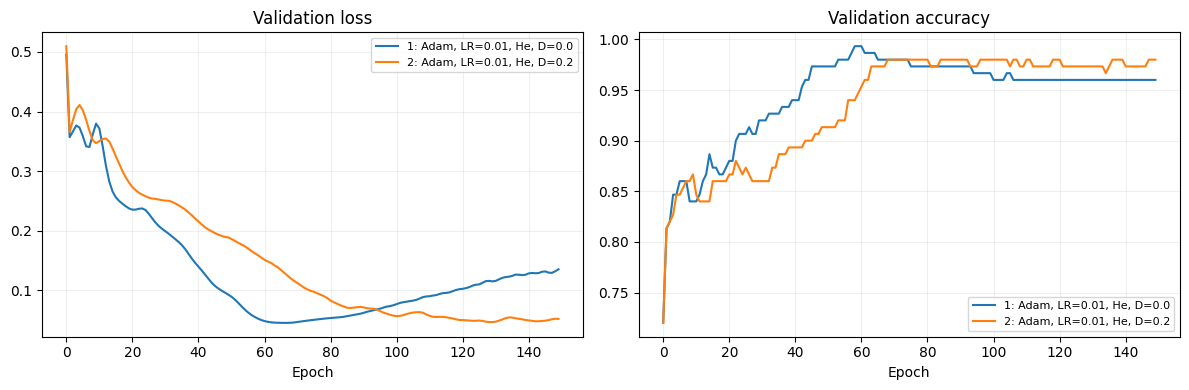

In [ ]:
if not experiments:
    print('Please run an experiment first. / まず実験を実行してください。')
else:
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    for i,r in enumerate(experiments[-6:]):
        s=r['settings'];label=f'{i+1}: {s["optimizer"]}, LR={s["lr"]}, {s["initialization"]}, D={s["dropout"]}'
        axs[0].plot(r['history']['val_loss'],label=label);axs[1].plot(r['history']['val_acc'],label=label)
    axs[0].set_title('Validation loss');axs[1].set_title('Validation accuracy')
    for ax in axs: ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend(fontsize=8)
    plt.tight_layout();plt.show()


## D. Classroom challenges / 講義での実験課題

1. **Learning rate / 学習率** — Hold other settings fixed. Compare `Adam 0.001` vs `Adam 0.01` vs `Adam 0.1`. Which converges faster or becomes unstable? / 他条件を固定して収束と不安定さを比較。
2. **Optimizer / 最適化法** — Compare `SGD`, `Momentum`, `Adam` at the **same** LR; note that each may favor different LR settings. / 同じ学習率で比較したあと、各方式に適切な学習率も探す。
3. **Initialization / 初期化** — ReLU + deep model: `Small`, `Xavier`, `He`. What happens to learning? / 深いReLUネットで比較。
4. **Dropout / 過学習** — Use `Moons` with higher noise, larger capacity, and compare `dropout=0` vs `0.3`. Check the gap between training and validation curves. / ノイズを増やして汎化の差を見る。
5. **Caution / 注意** — An observed difference in a single run is not a universal ranking. Try multiple seeds when interpreting results. / 1回の結果を普遍的な順位と捉えない。

**Discuss / 考察:** Why is dropout not guaranteed to reduce training loss? Why can Adam and SGD require different learning rates?  
**Next / 次へ:** Explore attention weights and context in Demo 2.
